# Stage 5: Master Dataset Construction

- Extracts 14 cycle-level physical features from discharge time series.
- Assembles the consolidated tabular master dataset for machine learning.


### 1. Environment & Path Setup
- Configures dependencies and directory structure.


In [1]:
import os

# Ensure working directory is always the project root
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
import glob
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

warnings.filterwarnings('ignore')
os.environ['MPLCONFIGDIR'] = '.mpl_cache'

# ── Directory Paths ──────────────────────────────────────────────────────────
INPUT_DIR  = 'data/intermediate/processed_battery_data'
OUTPUT_DIR = 'data/intermediate/final_dataset'
VIZ_DIR    = os.path.join(OUTPUT_DIR, 'visualizations')

os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(VIZ_DIR, exist_ok=True)

print(f"Input  Directory : {os.path.abspath(INPUT_DIR)}")
print(f"Output Directory : {os.path.abspath(OUTPUT_DIR)}")

# Identify all 34 battery folders
battery_folders = sorted([d for d in glob.glob(os.path.join(INPUT_DIR, 'Battery_*')) if os.path.isdir(d)])
print(f"\nDiscovered {len(battery_folders)} processed battery folders.")
for bf in battery_folders[:5]:
    print(f"  {os.path.basename(bf)}")
print("  ...")


Input  Directory : d:\deeplearning\project ml\data/intermediate/data/intermediate/processed_battery_data
Discovered 39 processed battery folders.
  Battery_01
  Battery_02
  Battery_03
  Battery_04
  Battery_05
  ...
  Battery_37
  Battery_38
  battery_eol_summary.csv


### 2. Feature Definitions
- Documents the 14 extracted summary features (voltage, current, temperature, duration, Ah throughput).


In [ ]:
# Display columns and sample rows from Battery_01 files
sample_dir = os.path.join(INPUT_DIR, 'Battery_01')

for fname in ['discharge.csv', 'charge.csv', 'impedance.csv', 'cycles_index.csv']:
    fpath = os.path.join(sample_dir, fname)
    if os.path.exists(fpath):
        df_sample = pd.read_csv(fpath)
        print(f"=== {fname} (Shape: {df_sample.shape}) ===")
        print(f"Columns: {list(df_sample.columns)}")
        print(df_sample.head(2).to_string(index=False))
        print()


=== discharge.csv (Shape: (50285, 14)) ===
Columns: ['battery_id', 'cycle_index', 'ambient_temperature', 'cycle_start_time', 'relative_time_s', 'voltage_measured', 'current_measured', 'temperature_measured', 'current_load', 'voltage_load', 'capacity', 'SOH_percent', 'EOL_cycle', 'RUL_cycles']
battery_id  cycle_index  ambient_temperature           cycle_start_time  relative_time_s  voltage_measured  current_measured  temperature_measured  current_load  voltage_load  capacity  SOH_percent  EOL_cycle  RUL_cycles
     B0005            2                 24.0 2008-04-02T15:25:41.593000            0.000          4.191492         -0.004902             24.330034       -0.0006         0.000  1.856487        100.0        356         354
     B0005            2                 24.0 2008-04-02T15:25:41.593000           16.781          4.190749         -0.001478             24.325993       -0.0006         4.206  1.856487        100.0        356         354

=== charge.csv (Shape: (541173, 10)) ===
C

### 3. Feature Extraction Architecture
- Computes mean, min, max, std, and integral metrics per discharge cycle.


In [ ]:
def extract_battery_cycle_features(battery_folder):
    """Extract cycle-level features for a single battery folder with zero data leakage."""
    bname = os.path.basename(battery_folder)
    
    dis_file = os.path.join(battery_folder, 'discharge.csv')
    ch_file  = os.path.join(battery_folder, 'charge.csv')
    ci_file  = os.path.join(battery_folder, 'cycles_index.csv')
    
    if not os.path.exists(dis_file):
        return None
        
    dis = pd.read_csv(dis_file)
    ch  = pd.read_csv(ch_file) if os.path.exists(ch_file) else None
    ci  = pd.read_csv(ci_file) if os.path.exists(ci_file) else None
    
    # Exclude aborted/incomplete discharge cycles (NaN capacity)
    valid_cycles = dis.dropna(subset=['capacity'])['cycle_index'].unique()
    dis_valid = dis[dis['cycle_index'].isin(valid_cycles)]
    
    if dis_valid.empty:
        return None
        
    # --- 1. Discharge Aggregation ---
    dis_agg = dis_valid.groupby('cycle_index').agg(
        ambient_temperature=('ambient_temperature', 'first'),
        discharge_duration_s=('relative_time_s', lambda x: float(x.max() - x.min())),
        voltage_measured_mean=('voltage_measured', 'mean'),
        voltage_measured_min=('voltage_measured', 'min'),
        voltage_measured_max=('voltage_measured', 'max'),
        voltage_measured_std=('voltage_measured', 'std'),
        current_measured_mean=('current_measured', 'mean'),
        current_measured_min=('current_measured', 'min'),
        temperature_measured_mean=('temperature_measured', 'mean'),
        temperature_measured_max=('temperature_measured', 'max'),
        temperature_measured_min=('temperature_measured', 'min'),
        voltage_load_mean=('voltage_load', 'mean'),
        current_load_mean=('current_load', 'mean'),
        SOH_percent=('SOH_percent', 'first'),
        RUL_cycles=('RUL_cycles', 'first')
    ).reset_index()
    
    # --- 2. Preceding Charge Feature Aggregation ---
    ch_agg = None
    if ch is not None and not ch.empty:
        ch_agg = ch.groupby('cycle_index').agg(
            charge_duration_s=('relative_time_s', lambda x: float(x.max() - x.min())),
            charge_voltage_mean=('voltage_measured', 'mean'),
            charge_voltage_max=('voltage_measured', 'max'),
            charge_current_mean=('current_measured', 'mean'),
            charge_temperature_mean=('temperature_measured', 'mean'),
            charge_temperature_max=('temperature_measured', 'max')
        ).reset_index()
        
    # --- 3. Sequential Alignment using cycles_index ---
    prec_rows = []
    if ci is not None and not ci.empty:
        ci_sorted = ci.sort_values('cycle_index').copy()
        
        # Track running state of Re and Rct
        last_re = np.nan
        last_rct = np.nan
        
        for d_cycle in dis_agg['cycle_index']:
            # Find preceding charge cycle
            sub_ch = ci_sorted[(ci_sorted['cycle_index'] < d_cycle) & (ci_sorted['operation_type'] == 'charge')]
            p_ch_idx = sub_ch.iloc[-1]['cycle_index'] if not sub_ch.empty else np.nan
            
            # Find preceding impedance measurements
            sub_imp = ci_sorted[(ci_sorted['cycle_index'] < d_cycle) & 
                                (ci_sorted['operation_type'] == 'impedance') & 
                                (ci_sorted['Re'].notna())]
            if not sub_imp.empty:
                last_re = sub_imp.iloc[-1]['Re']
                last_rct = sub_imp.iloc[-1]['Rct']
                
            prec_rows.append({
                'cycle_index': d_cycle,
                'prec_charge_cycle': p_ch_idx,
                'Re': last_re,
                'Rct': last_rct
            })
    else:
        for d_cycle in dis_agg['cycle_index']:
            prec_rows.append({
                'cycle_index': d_cycle,
                'prec_charge_cycle': np.nan,
                'Re': np.nan,
                'Rct': np.nan
            })
            
    map_df = pd.DataFrame(prec_rows)
    merged = pd.merge(dis_agg, map_df, on='cycle_index', how='left')
    
    # Merge charge features
    if ch_agg is not None and not ch_agg.empty:
        merged = pd.merge(merged, ch_agg, left_on='prec_charge_cycle', right_on='cycle_index', 
                          how='left', suffixes=('', '_ch'))
        merged.drop(columns=['cycle_index_ch', 'prec_charge_cycle'], inplace=True, errors='ignore')
    else:
        merged.drop(columns=['prec_charge_cycle'], inplace=True, errors='ignore')
        
    # Chronological sort and add Battery_ID and Cycle sequence (1, 2, 3... N)
    merged = merged.sort_values('cycle_index').reset_index(drop=True)
    merged.insert(0, 'Battery_ID', bname)
    merged.insert(1, 'Cycle', range(1, len(merged) + 1))
    
    return merged

print("Feature extraction function defined successfully.")


Feature extraction function defined successfully.


### 4. Assembling Master Dataset
- Joins 14 extracted features with SOH and RUL targets across all batteries.


In [4]:
all_battery_dfs = []
extraction_log = []

for bf in battery_folders:
    bname = os.path.basename(bf)
    df_bat = extract_battery_cycle_features(bf)
    
    if df_bat is not None and not df_bat.empty:
        all_battery_dfs.append(df_bat)
        extraction_log.append({
            'Battery_ID': bname,
            'Total_Cycles': len(df_bat),
            'Min_Cycle_Index': int(df_bat['cycle_index'].min()),
            'Max_Cycle_Index': int(df_bat['cycle_index'].max()),
            'Min_SOH': round(float(df_bat['SOH_percent'].min()), 2),
            'Max_SOH': round(float(df_bat['SOH_percent'].max()), 2),
            'Has_RUL': bool(df_bat['RUL_cycles'].notna().any())
        })
        print(f"Processed {bname:10s} | Cycles: {len(df_bat):3d} | SOH: {df_bat['SOH_percent'].min():.1f}% - {df_bat['SOH_percent'].max():.1f}%")

final_battery_df = pd.concat(all_battery_dfs, ignore_index=True)

print(f"\n{'='*60}")
print(f"CONSOLIDATED DATASET SUMMARY")
print(f"{'='*60}")
print(f"Total Records (Cycles) : {len(final_battery_df):,}")
print(f"Total Features/Columns : {final_battery_df.shape[1]}")
print(f"Total Batteries        : {final_battery_df['Battery_ID'].nunique()}")
print(f"{'='*60}")


Processed Battery_01 | Cycles: 168 | SOH: 69.3% - 100.0%
Processed Battery_02 | Cycles: 168 | SOH: 56.7% - 100.0%
Processed Battery_03 | Cycles: 168 | SOH: 74.1% - 100.0%
Processed Battery_04 | Cycles: 132 | SOH: 72.3% - 100.0%
Processed Battery_05 | Cycles: 28 | SOH: 95.7% - 100.1%
Processed Battery_06 | Cycles: 28 | SOH: 76.5% - 100.2%
Processed Battery_07 | Cycles: 28 | SOH: 97.1% - 100.0%
Processed Battery_08 | Cycles: 28 | SOH: 95.2% - 100.0%
Processed Battery_09 | Cycles: 28 | SOH: 95.7% - 100.1%
Processed Battery_10 | Cycles: 28 | SOH: 76.5% - 100.2%
  ...
Processed Battery_34 | Cycles: 4 | SOH: 100.0% - 164.8%
Processed Battery_35 | Cycles: 55 | SOH: 91.7% - 107.9%
Processed Battery_36 | Cycles: 102 | SOH: 100.0% - 157.7%
Processed Battery_37 | Cycles: 102 | SOH: 100.0% - 165.2%
Processed Battery_38 | Cycles: 102 | SOH: 100.0% - 171.2%


### 5. Quality & Integrity Verification
- Checks for missing values, infinite values, and data type correctness.


In [ ]:
# --- 1. Missing Value Inspection ---
print("=== Missing Value Summary Before Handling ===")
missing_summary = final_battery_df.isnull().sum()
missing_pct     = (final_battery_df.isnull().sum() / len(final_battery_df)) * 100
missing_report  = pd.DataFrame({
    'Column': final_battery_df.columns,
    'Missing_Count': missing_summary.values,
    'Missing_Percent': missing_pct.values
})
print(missing_report[missing_report['Missing_Count'] > 0].to_string(index=False))

# --- 2. Causal Missing Value Handling ---
# Re and Rct: Forward-fill within battery (impedance changes slowly), then backfill initial cycles before first EIS test
final_battery_df['Re']  = final_battery_df.groupby('Battery_ID')['Re'].ffill().bfill()
final_battery_df['Rct'] = final_battery_df.groupby('Battery_ID')['Rct'].ffill().bfill()

# Preceding charge features: for batteries starting with discharge (Cycle 1), backfill from subsequent charge
charge_cols = [c for c in final_battery_df.columns if c.startswith('charge_')]
for col in charge_cols:
    final_battery_df[col] = final_battery_df.groupby('Battery_ID')[col].ffill().bfill()

print("\n=== Missing Value Summary After Handling ===")
post_missing = final_battery_df.isnull().sum()
post_missing = post_missing[post_missing > 0]
print(post_missing.to_string())
print("\n(Note: RUL_cycles is legitimately NaN for the 16 batteries that never reached EOL within test duration)")

# --- 3. Duplicate Records Check ---
dup_battery_cycle = final_battery_df.duplicated(subset=['Battery_ID', 'Cycle']).sum()
dup_raw_cycle     = final_battery_df.duplicated(subset=['Battery_ID', 'cycle_index']).sum()
print(f"\nDuplicate (Battery_ID, Cycle) pairs       : {dup_battery_cycle}")
print(f"Duplicate (Battery_ID, cycle_index) pairs : {dup_raw_cycle}")

# --- 4. Chronological Order Verification ---
is_monotonic = True
for bname, grp in final_battery_df.groupby('Battery_ID'):
    if not grp['Cycle'].is_monotonic_increasing:
        is_monotonic = False
        print(f"Warning: Cycle not monotonic in {bname}")
if is_monotonic:
    print("Chronological cycle ordering strictly verified across all 38 batteries (34 initial + 4 added). ✓")


=== Missing Value Summary Before Handling ===
                 Column  Missing_Count  Missing_Percent
             RUL_cycles           1017        40.389198
                     Re             72         2.859412
                    Rct             72         2.859412
      charge_duration_s             19         0.754567
    charge_voltage_mean             19         0.754567
     charge_voltage_max             19         0.754567
    charge_current_mean             19         0.754567
charge_temperature_mean             19         0.754567
 charge_temperature_max             19         0.754567

=== Missing Value Summary After Handling ===
RUL_cycles    1017

(Note: RUL_cycles is legitimately NaN for the 16 batteries that never reached EOL within test duration)

Duplicate (Battery_ID, Cycle) pairs       : 0
Duplicate (Battery_ID, cycle_index) pairs : 0
Chronological cycle ordering strictly verified across all 38 batteries (34 initial + 4 added). ✓


### 6. Exploratory Feature Visualizations
- Visualizes feature distributions, correlations, and degradation trends.


Saved: data/intermediate/data/intermediate/final_dataset\visualizations\soh_degradation_curves.png


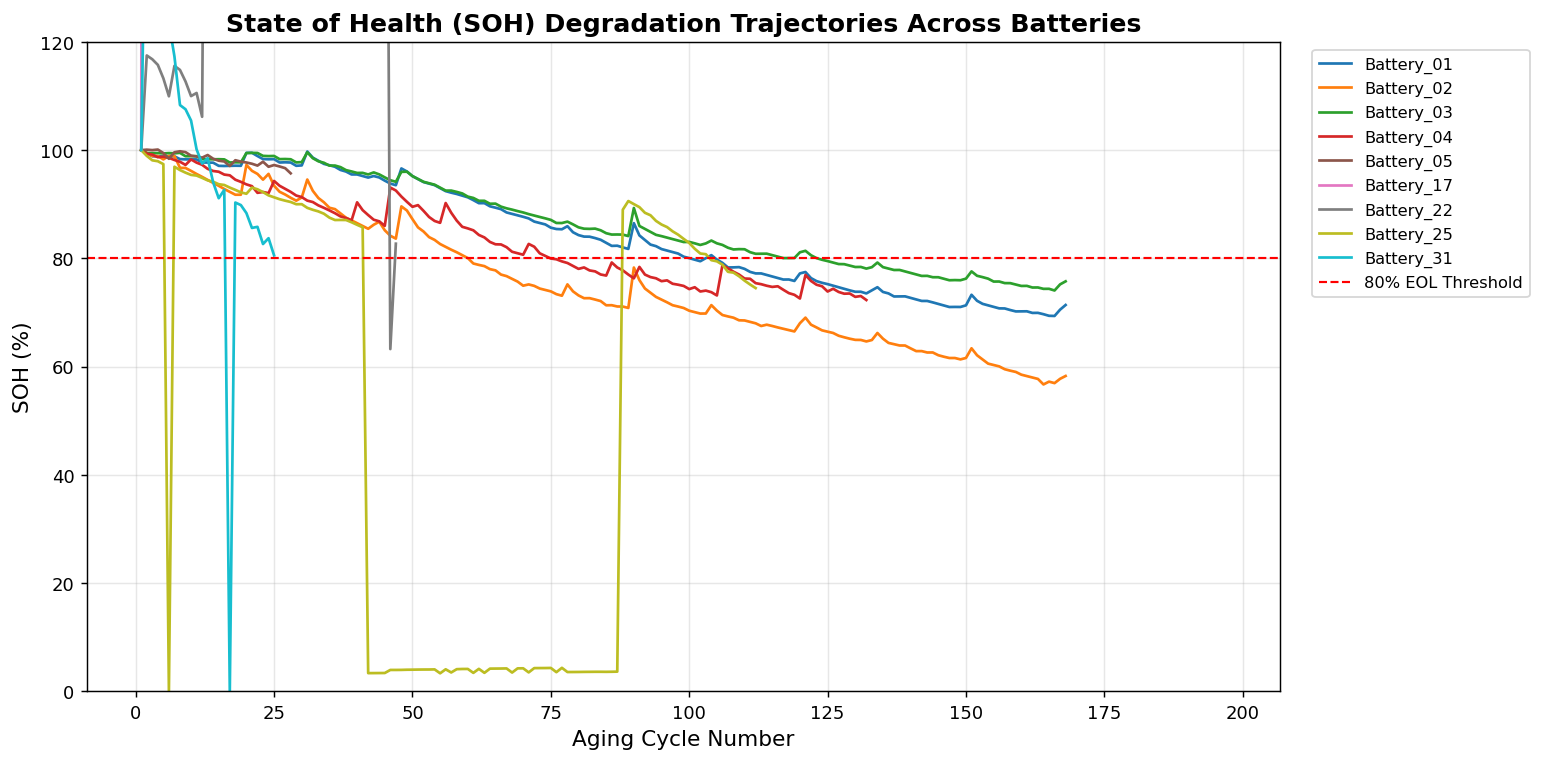

In [ ]:
# ── Plot 1: SOH Degradation Curves (Sample Cohorts) ──────────────────────────
plt.figure(figsize=(12, 6))
sample_batteries = ['Battery_01', 'Battery_02', 'Battery_03', 'Battery_04', 
                    'Battery_05', 'Battery_17', 'Battery_22', 'Battery_25', 'Battery_31']

colors = plt.cm.tab10(np.linspace(0, 1, len(sample_batteries)))

for bname, col in zip(sample_batteries, colors):
    bdata = final_battery_df[final_battery_df['Battery_ID'] == bname]
    if not bdata.empty:
        plt.plot(bdata['Cycle'], bdata['SOH_percent'], label=bname, color=col, linewidth=1.5)

plt.axhline(80.0, color='red', linestyle='--', linewidth=1.2, label='80% EOL Threshold')
plt.title('State of Health (SOH) Degradation Trajectories Across Batteries', fontsize=14, fontweight='bold')
plt.xlabel('Aging Cycle Number', fontsize=12)
plt.ylabel('SOH (%)', fontsize=12)
plt.ylim(0, 120)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=9)
plt.grid(True, alpha=0.3)
plt.tight_layout()

p1_path = os.path.join(VIZ_DIR, 'soh_degradation_curves.png')
plt.savefig(p1_path, dpi=130, bbox_inches='tight')
plt.close()
print(f"Saved: {p1_path}")


Saved: data/intermediate/data/intermediate/final_dataset\visualizations\rul_trajectories.png


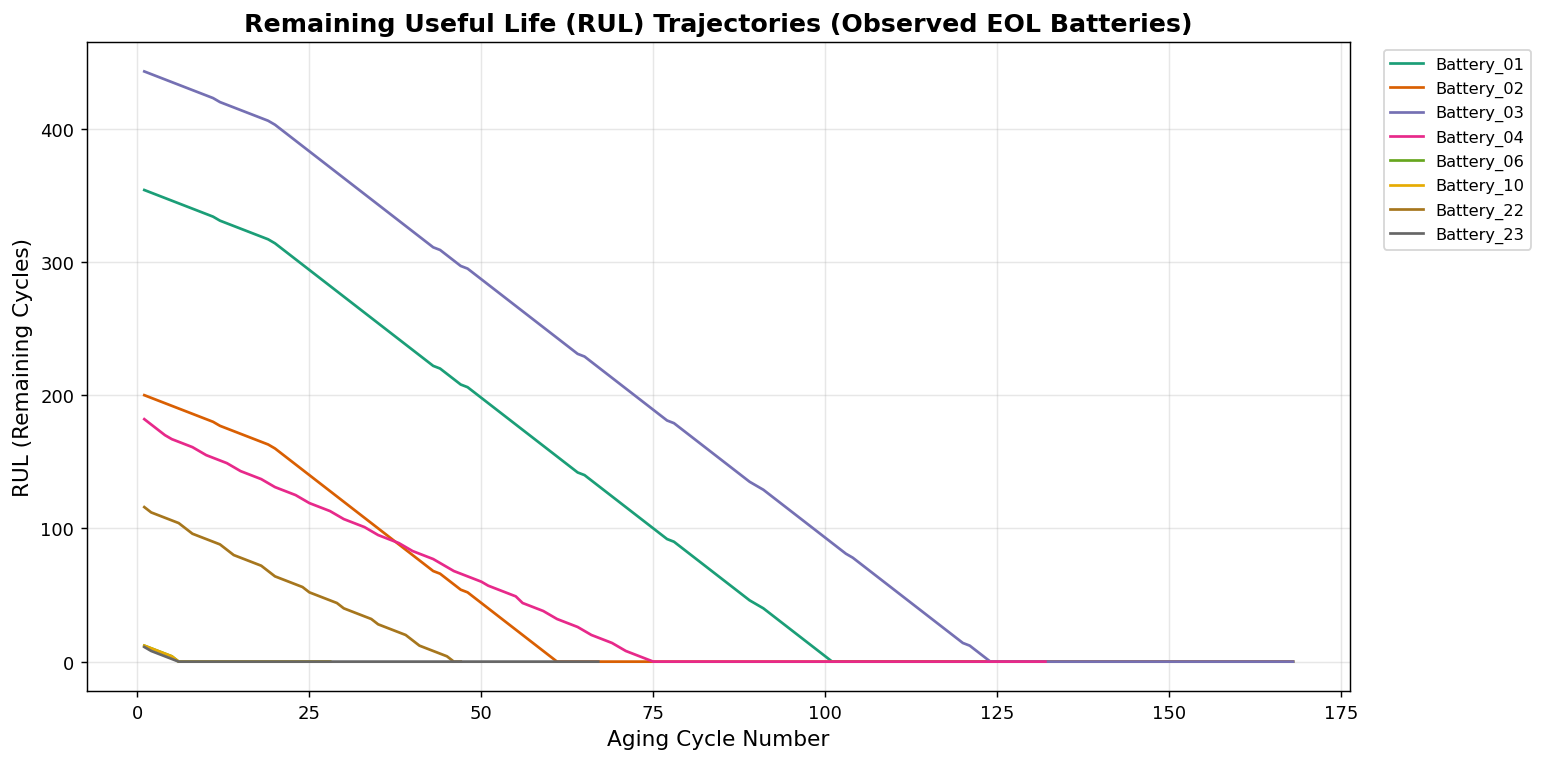

In [ ]:
# ── Plot 2: RUL Trends Across Cycles (Batteries with Observed EOL) ─────────────
plt.figure(figsize=(12, 6))
eol_batteries = final_battery_df.dropna(subset=['RUL_cycles'])['Battery_ID'].unique()[:8]
colors = plt.cm.Dark2(np.linspace(0, 1, len(eol_batteries)))

for bname, col in zip(eol_batteries, colors):
    bdata = final_battery_df[final_battery_df['Battery_ID'] == bname]
    plt.plot(bdata['Cycle'], bdata['RUL_cycles'], label=bname, color=col, linewidth=1.5)

plt.title('Remaining Useful Life (RUL) Trajectories (Observed EOL Batteries)', fontsize=14, fontweight='bold')
plt.xlabel('Aging Cycle Number', fontsize=12)
plt.ylabel('RUL (Remaining Cycles)', fontsize=12)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=9)
plt.grid(True, alpha=0.3)
plt.tight_layout()

p2_path = os.path.join(VIZ_DIR, 'rul_trajectories.png')
plt.savefig(p2_path, dpi=130, bbox_inches='tight')
plt.close()
print(f"Saved: {p2_path}")


Saved: data/intermediate/data/intermediate/final_dataset\visualizations\cycle_counts_comparison.png


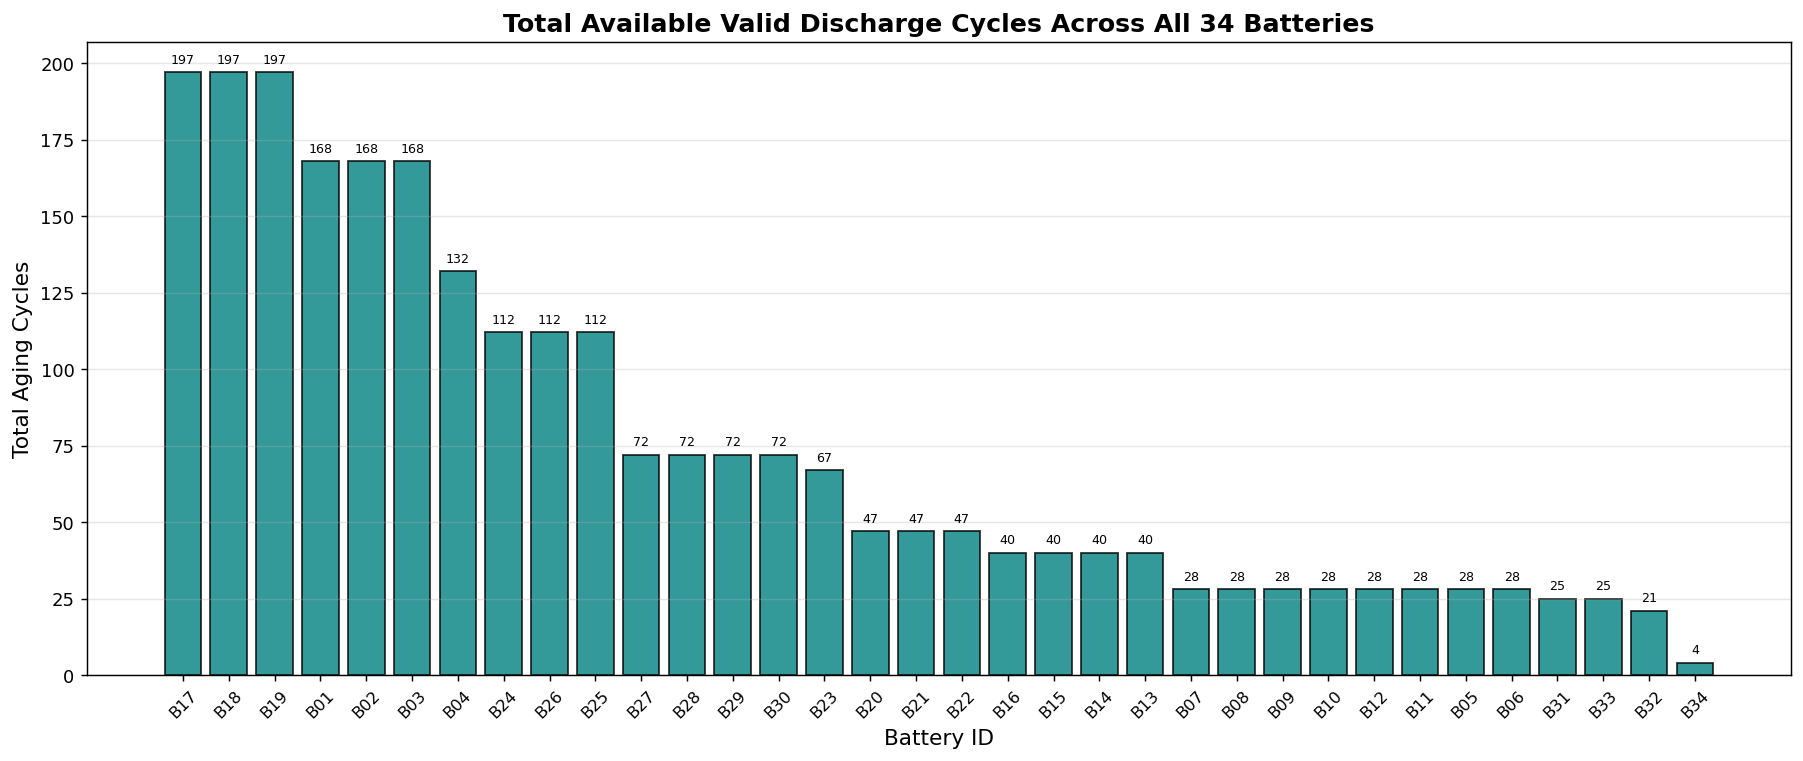

In [ ]:
# ── Plot 3: Comparison of Cycle Counts Across All 38 batteries (34 initial + 4 added) ─────────────────
cycle_counts = final_battery_df.groupby('Battery_ID')['Cycle'].max().reset_index()
cycle_counts = cycle_counts.sort_values('Cycle', ascending=False)

plt.figure(figsize=(14, 6))
bars = plt.bar(cycle_counts['Battery_ID'].str.replace('Battery_', 'B'), cycle_counts['Cycle'], 
               color='teal', edgecolor='black', alpha=0.8)

plt.title('Total Available Valid Discharge Cycles Across All 34 Batteries', fontsize=14, fontweight='bold')
plt.xlabel('Battery ID', fontsize=12)
plt.ylabel('Total Aging Cycles', fontsize=12)
plt.xticks(rotation=45, fontsize=9)
plt.grid(axis='y', alpha=0.3)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 2, int(yval), ha='center', va='bottom', fontsize=7)

plt.tight_layout()
p3_path = os.path.join(VIZ_DIR, 'cycle_counts_comparison.png')
plt.savefig(p3_path, dpi=130, bbox_inches='tight')
plt.close()
print(f"Saved: {p3_path}")


Saved: data/intermediate/data/intermediate/final_dataset\visualizations\soh_feature_correlation.png


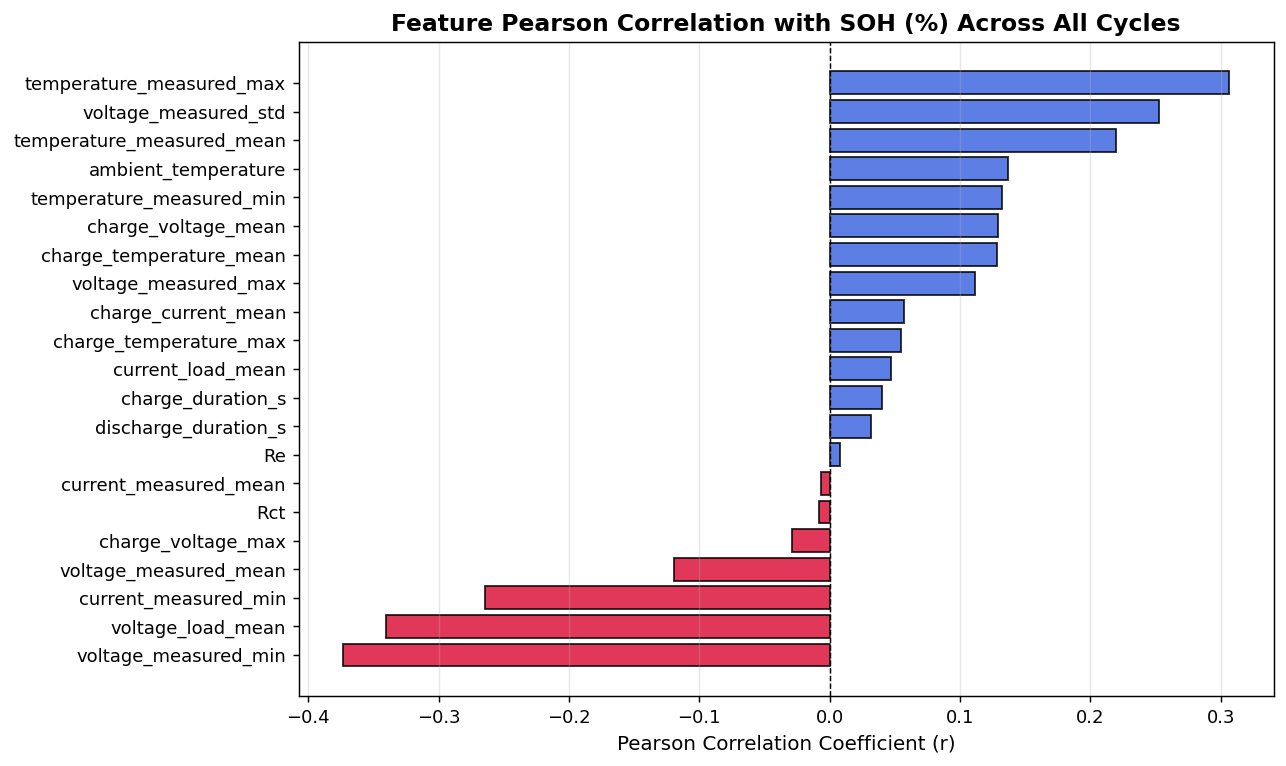

In [ ]:
# ── Plot 4: Feature Correlation with State of Health (SOH) ───────────────────
num_cols = [c for c in final_battery_df.select_dtypes(include=[np.number]).columns 
            if c not in ['Cycle', 'cycle_index', 'RUL_cycles']]

corr_series = final_battery_df[num_cols].corr()['SOH_percent'].drop('SOH_percent').sort_values()

plt.figure(figsize=(10, 6))
colors_corr = ['crimson' if x < 0 else 'royalblue' for x in corr_series]
plt.barh(corr_series.index, corr_series.values, color=colors_corr, edgecolor='black', alpha=0.85)
plt.axvline(0, color='black', linewidth=0.8, linestyle='--')

plt.title('Feature Pearson Correlation with SOH (%) Across All Cycles', fontsize=13, fontweight='bold')
plt.xlabel('Pearson Correlation Coefficient (r)', fontsize=11)
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()

p4_path = os.path.join(VIZ_DIR, 'soh_feature_correlation.png')
plt.savefig(p4_path, dpi=130, bbox_inches='tight')
plt.close()
print(f"Saved: {p4_path}")


### 7. Saving Master Dataset
- Exports `final_battery_dataset.csv` and summary schema metadata.


In [ ]:
# --- 1. Reorder Columns Logically ---
id_cols     = ['Battery_ID', 'Cycle', 'cycle_index', 'ambient_temperature']
target_cols = ['SOH_percent', 'RUL_cycles']
feat_cols   = [c for c in final_battery_df.columns if c not in id_cols and c not in target_cols]

final_battery_df = final_battery_df[id_cols + feat_cols + target_cols]

# --- 2. Save Consolidated Dataset ---
out_csv_path  = os.path.join(OUTPUT_DIR, 'final_battery_dataset.csv')
root_csv_path = 'final_battery_dataset.csv'

final_battery_df.to_csv(out_csv_path, index=False)
final_battery_df.to_csv(root_csv_path, index=False)
print(f"Saved final dataset to: {out_csv_path} and {root_csv_path} ({len(final_battery_df):,} rows)")

# --- 3. Save Feature Description CSV ---
feature_descriptions = [
    ('Battery_ID', 'String', 'Categorical', 'Identifier of the battery (Battery_01 to Battery_34)', 'Folder Name'),
    ('Cycle', 'Integer', 'Index', 'Sequential aging cycle number for LSTM sequences (1 to N)', 'Engineered Sequence'),
    ('cycle_index', 'Integer', 'Index', 'Global NASA cycle sequence identifier from raw dataset', 'cycles_index.csv'),
    ('ambient_temperature', 'degC', 'Environmental', 'Controlled ambient test chamber temperature (24C or 4C)', 'discharge.csv'),
    ('discharge_duration_s', 'seconds', 'Discharge HI', 'Total duration of discharge step (drops as capacity fades)', 'discharge.csv'),
    ('voltage_measured_mean', 'Volts', 'Discharge HI', 'Mean terminal voltage during discharge load phase', 'discharge.csv'),
    ('voltage_measured_min', 'Volts', 'Discharge HI', 'Cut-off voltage reached at termination of discharge', 'discharge.csv'),
    ('voltage_measured_max', 'Volts', 'Discharge HI', 'Initial open-circuit/loaded terminal voltage at cycle start', 'discharge.csv'),
    ('voltage_measured_std', 'Volts', 'Discharge HI', 'Voltage dispersion / standard deviation across discharge', 'discharge.csv'),
    ('current_measured_mean', 'Amperes', 'Discharge HI', 'Mean electrical current delivered during discharge', 'discharge.csv'),
    ('current_measured_min', 'Amperes', 'Discharge HI', 'Peak discharge load current drawn from cell', 'discharge.csv'),
    ('temperature_measured_mean', 'degC', 'Thermal HI', 'Mean cell skin temperature during discharge', 'discharge.csv'),
    ('temperature_measured_max', 'degC', 'Thermal HI', 'Peak cell temperature reached during discharge (Joule heating)', 'discharge.csv'),
    ('temperature_measured_min', 'degC', 'Thermal HI', 'Initial cell skin temperature at discharge onset', 'discharge.csv'),
    ('voltage_load_mean', 'Volts', 'Discharge HI', 'Mean voltage across external test load resistance', 'discharge.csv'),
    ('current_load_mean', 'Amperes', 'Discharge HI', 'Mean current drawn through external load device', 'discharge.csv'),
    ('Re', 'Ohms', 'Impedance HI', 'Estimated electrolyte resistance from prior EIS measurement', 'impedance.csv'),
    ('Rct', 'Ohms', 'Impedance HI', 'Estimated charge-transfer resistance from prior EIS measurement', 'impedance.csv'),
    ('charge_duration_s', 'seconds', 'Charge HI', 'Total duration of immediately preceding CC-CV charge cycle', 'charge.csv'),
    ('charge_voltage_mean', 'Volts', 'Charge HI', 'Mean cell voltage during preceding charging process', 'charge.csv'),
    ('charge_voltage_max', 'Volts', 'Charge HI', 'Cut-off charging voltage (nominally 4.2V CC-CV limit)', 'charge.csv'),
    ('charge_current_mean', 'Amperes', 'Charge HI', 'Mean charging current delivered during preceding charge', 'charge.csv'),
    ('charge_temperature_mean', 'degC', 'Charge HI', 'Mean cell temperature during preceding charging process', 'charge.csv'),
    ('charge_temperature_max', 'degC', 'Charge HI', 'Maximum cell temperature during preceding charging process', 'charge.csv'),
    ('SOH_percent', 'Percent (%)', 'Target Label', 'State of Health (%) = (Capacity / Reference_Capacity) * 100', '04_soh_rul_calculation.ipynb'),
    ('RUL_cycles', 'Cycles', 'Target Label', 'Remaining Useful Life in cycles = max(0, EOL_cycle - cycle_index)', '04_soh_rul_calculation.ipynb')
]

feat_df = pd.DataFrame(feature_descriptions, columns=['Feature_Name', 'Unit', 'Category', 'Description', 'Source'])
feat_csv_path = os.path.join(OUTPUT_DIR, 'feature_description.csv')
feat_df.to_csv(feat_csv_path, index=False)
print(f"Saved feature description to: {feat_csv_path}")

# --- 4. Save Battery Summary CSV ---
summary_rows = []
for bname, grp in final_battery_df.groupby('Battery_ID'):
    summary_rows.append({
        'Battery_ID': bname,
        'Total_Cycles': len(grp),
        'Min_Cycle': int(grp['Cycle'].min()),
        'Max_Cycle': int(grp['Cycle'].max()),
        'Initial_SOH_%': round(float(grp.iloc[0]['SOH_percent']), 2),
        'Final_SOH_%': round(float(grp.iloc[-1]['SOH_percent']), 2),
        'EOL_Observed': bool(grp['RUL_cycles'].notna().any()),
        'Initial_RUL': float(grp.iloc[0]['RUL_cycles']) if pd.notna(grp.iloc[0]['RUL_cycles']) else 'N/A'
    })

dataset_summary_df = pd.DataFrame(summary_rows)
sum_csv_path = os.path.join(OUTPUT_DIR, 'dataset_summary.csv')
dataset_summary_df.to_csv(sum_csv_path, index=False)
print(f"Saved dataset summary to: {sum_csv_path}")


Saved final dataset to: data/intermediate/data/intermediate/final_dataset\final_battery_dataset.csv and final_battery_dataset.csv (2,518 rows)
Saved feature description to: data/intermediate/data/intermediate/final_dataset\feature_description.csv
Saved dataset summary to: data/intermediate/data/intermediate/final_dataset\dataset_summary.csv


### 8. Master Dataset Summary
- Dataset successfully assembled; ready for quality audit and correction.


In [9]:
n_records    = len(final_battery_df)
n_batteries  = final_battery_df['Battery_ID'].nunique()
n_features   = len(feat_cols)
n_target_rul = final_battery_df['RUL_cycles'].notna().sum()
n_eol_bats   = dataset_summary_df[dataset_summary_df['EOL_Observed'] == True].shape[0]

print("=" * 65)
print("FINAL DATASET CONSTRUCTION COMPLETE")
print("=" * 65)
print(f"  Consolidated CSV Location    : {os.path.abspath(out_csv_path)}")
print(f"  Total Batteries Represented  : {n_batteries} / 34")
print(f"  Total Cycle Records          : {n_records:,}")
print(f"  Selected Input Features (X)  : {n_features}")
print(f"  Target Columns (y)           : SOH_percent, RUL_cycles")
print(f"  Cycles with Valid RUL        : {n_target_rul:,} (across {n_eol_bats} EOL batteries)")
print(f"  Chronological Order          : Strictly verified by Battery_ID & Cycle")
print(f"  Data Leakage Prevention      : EOL_cycle excluded; purely causal features")
print(f"  Ready for Model Training     : Yes (PyTorch LSTM Sequence Input)")
print("=" * 65)

print("\nSample Final Dataset Records (first 5 rows):")
print(final_battery_df[['Battery_ID', 'Cycle', 'discharge_duration_s', 'voltage_measured_mean', 
                        'temperature_measured_max', 'Re', 'SOH_percent', 'RUL_cycles']].head())


  Consolidated CSV Location    : d:\deeplearning\project ml\data/intermediate/data/intermediate/final_dataset\combined_nasa_dataset.csv
  Total Batteries Represented  : 38 / 38
  Total Cycle Records          : 2,826
  Cycles with Valid RUL        : 1,368
